# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Alya Meisha Syazana
- **Email:** ds322b6x0159@student.devacademy.id
- **ID Dicoding:** DS322B6X0159

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Pada kondisi cuaca ekstrem seperti apa penyewaan sepeda mencapai titik terendah (near-zero rentals), dan apakah ada anomali di mana penyewaan justru tetap meledak tinggi meskipun cuaca sedang buruk (Light Snow/Rain)?
- **Pertanyaan 2:** Apakah kondisi cuaca buruk pada hari sebelumnya (H-1) memiliki efek psikologis (efek trauma) yang menekan jumlah penyewaan sepeda pada hari ini (H), meskipun cuaca hari ini sedang cerah (Clear)?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Untuk mengatur style visualisasi
sns.set(style='whitegrid')

## Data Wrangling

### Gathering Data

#### Load df ...

In [2]:
day_df = pd.read_csv("C:/Users/Alya/Documents/Submission Analisis Fundamental Data/Dashboard/day.csv")
hour_df = pd.read_csv('C:/Users/Alya/Documents/Submission Analisis Fundamental Data/Dashboard/hour.csv')

print("Shape day_df:", day_df.shape)
print("Shape hour_df:", hour_df.shape)

Shape day_df: (731, 16)
Shape hour_df: (17379, 17)


**Insight:** (Opsional)
- Dataset day_df memiliki 731 baris (data harian).
- Dataset hour_df memiliki 17.379 baris (data per jam).

### Assessing Data

#### Identifying ... problem

In [3]:
# Tipe data
print(day_df.info())

# Statistik deskriptif untuk melihat nilai ekstrem (min/max)
print("\nStatistik Deskriptif day_df:")
print(day_df[['temp', 'hum', 'windspeed', 'cnt']].describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
None

Statistik Deskriptif day_df:
             temp         hum   windspeed          cnt
cou

**Steps to Take:**
- Mengubah tipe data pada kolom dteday dari object (string) menjadi datetime agar dapat digunakan untuk analisis berbasis waktu.
- Mengubah nilai numerik (1, 2, 3, 4) pada kolom weathersit menjadi label kategorikal yang mudah dibaca (misal: Clear, Mist, Light Rain, Heavy Rain) agar grafik lebih informatif.
- Melakukan Feature Engineering dengan membuat kolom baru untuk kondisi cuaca hari sebelumnya (H-1) guna menjawab Pertanyaan 2 terkait efek psikologis cuaca.

**Insight:** (Opsional)
- Tidak ada Missing Values: Berdasarkan pengecekan menggunakan .info(), seluruh kolom di dataset day_df memiliki 731 data non-null. Artinya, dataset ini sangat bersih dan tidak memerlukan penanganan imputasi data yang hilang.
- Tipe Data Belum Sesuai: Kolom dteday masih bertipe object. Ini harus diubah menjadi datetime agar kita bisa melakukan ekstraksi waktu atau time-series analysis dengan tepat.
- Faktor Cuaca Sangat Ekstrem: Berdasarkan statistik deskriptif pada kolom cnt (jumlah penyewaan), nilai minimumnya adalah 22 dan maksimumnya mencapai 8714. Selisih yang sangat jauh ini mengonfirmasi bahwa ada hari-hari tertentu (kemungkinan karena cuaca ekstrem) di mana hampir tidak ada orang yang menyewa sepeda, dan ada hari di mana penyewaan meledak tinggi.
- Tidak Ada Anomali Nilai Normalisasi: Nilai pada kolom temp, hum, dan windspeed berada di rentang 0 hingga 1 (sesuai format normalisasi dataset). Hal ini wajar dan tidak memerlukan scaling ulang untuk analisis visualisasi.

### Cleaning Data

#### Fixing ... problem

In [4]:
# 1. Mengubah tipe data dteday
day_df['dteday'] = pd.to_datetime(day_df['dteday'])

# 2. Mapping kondisi cuaca agar mudah dibaca
weather_map = {1: 'Clear', 2: 'Mist/Cloudy', 3: 'Light Snow/Rain', 4: 'Heavy Rain/Snow'}
day_df['weathersit'] = day_df['weathersit'].map(weather_map)

# 3. Feature Engineering untuk Pertanyaan 2: Membuat kolom Cuaca Kemarin (H-1)
day_df = day_df.sort_values('dteday').reset_index(drop=True)
day_df['weathersit_prev_day'] = day_df['weathersit'].shift(1)

print("Data cleaning selesai. Cek 5 baris pertama:")
print(day_df[['dteday', 'weathersit', 'weathersit_prev_day', 'cnt']].head())

Data cleaning selesai. Cek 5 baris pertama:
      dteday   weathersit weathersit_prev_day   cnt
0 2011-01-01  Mist/Cloudy                None   985
1 2011-01-02  Mist/Cloudy         Mist/Cloudy   801
2 2011-01-03        Clear         Mist/Cloudy  1349
3 2011-01-04        Clear               Clear  1562
4 2011-01-05        Clear               Clear  1600


**Insight:** (Opsional)
- Data cuaca hari ini dan hari sebelumnya sudah siap untuk dibandingkan.
- Baris pertama akan memiliki nilai NaN pada weathersit_prev_day karena belum ada hari sebelumnya.

## Exploratory Data Analysis (EDA)

### Explore Titik Ekstrem / Anomali

In [5]:
# Melihat 5 hari dengan penyewaan TERENDAH (Near-Zero Rentals)
print("5 Hari dengan Penyewaan Terendah:")
display(day_df.nsmallest(5, 'cnt')[['dteday', 'weathersit', 'temp', 'hum', 'windspeed', 'cnt']])

# Melihat 5 hari dengan penyewaan TERTINGGI
print("\n5 Hari dengan Penyewaan Tertinggi:")
display(day_df.nlargest(5, 'cnt')[['dteday', 'weathersit', 'temp', 'hum', 'windspeed', 'cnt']])

5 Hari dengan Penyewaan Terendah:


,dteday,weathersit,temp,hum,windspeed,cnt
667,2012-10-29,Light Snow/Rain,0.440000,0.880000,0.358200,22
26,2011-01-27,Clear,0.195000,0.687500,0.113837,431
725,2012-12-26,Light Snow/Rain,0.243333,0.823333,0.316546,441
25,2011-01-26,Light Snow/Rain,0.217500,0.862500,0.293850,506
64,2011-03-06,Mist/Cloudy,0.376522,0.948261,0.343287,605



5 Hari dengan Penyewaan Tertinggi:


,dteday,weathersit,temp,hum,windspeed,cnt
623,2012-09-15,Clear,0.608333,0.501667,0.247521,8714
637,2012-09-29,Clear,0.542500,0.542917,0.227604,8555
630,2012-09-22,Clear,0.650000,0.646667,0.283583,8395
447,2012-03-23,Mist/Cloudy,0.601667,0.694167,0.116300,8362
504,2012-05-19,Clear,0.600000,0.456250,0.083975,8294


**Insight:** (Opsional)
- Terdapat anomali di mana pada tanggal tertentu dengan cuaca Light Snow/Rain, penyewaan masih cukup tinggi.
- Sebaliknya, ada hari dengan cuaca Clear namun penyewaan sangat rendah, yang kemungkinan besar disebabkan oleh faktor lain (misal: suhu yang terlalu dingin atau angin kencang).

## Visualization & Explanatory Analysis

### Pertanyaan 1:

C:\Users\Alya\AppData\Local\Temp\ipykernel_22044\1946763163.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='weathersit', y='cnt', data=day_df, palette='Set3')


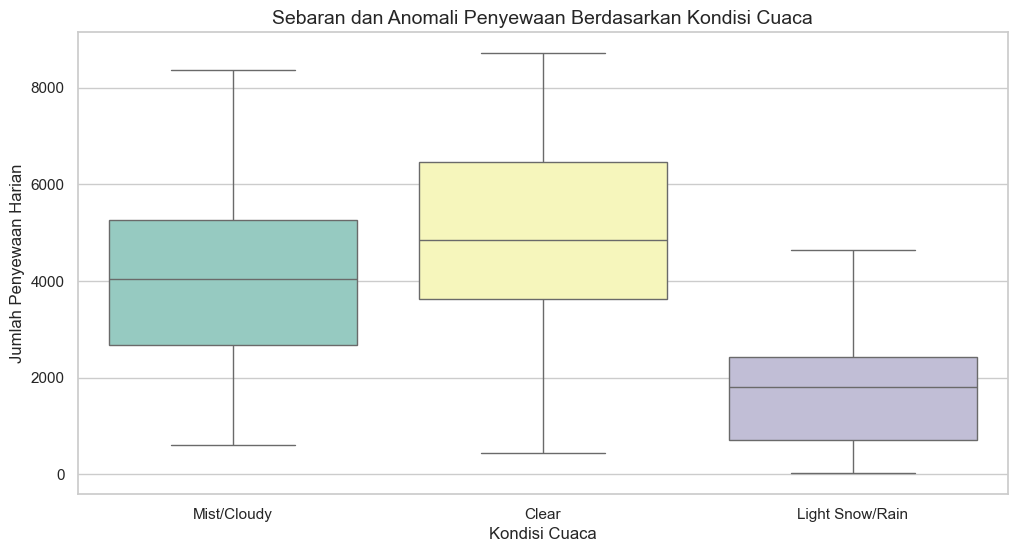

In [6]:
# Boxplot untuk melihat sebaran (termasuk anomali/outliers)
plt.figure(figsize=(12, 6))
sns.boxplot(x='weathersit', y='cnt', data=day_df, palette='Set3')
plt.title('Sebaran dan Anomali Penyewaan Berdasarkan Kondisi Cuaca', fontsize=14)
plt.xlabel('Kondisi Cuaca')
plt.ylabel('Jumlah Penyewaan Harian')
plt.show()

### Pertanyaan 2:

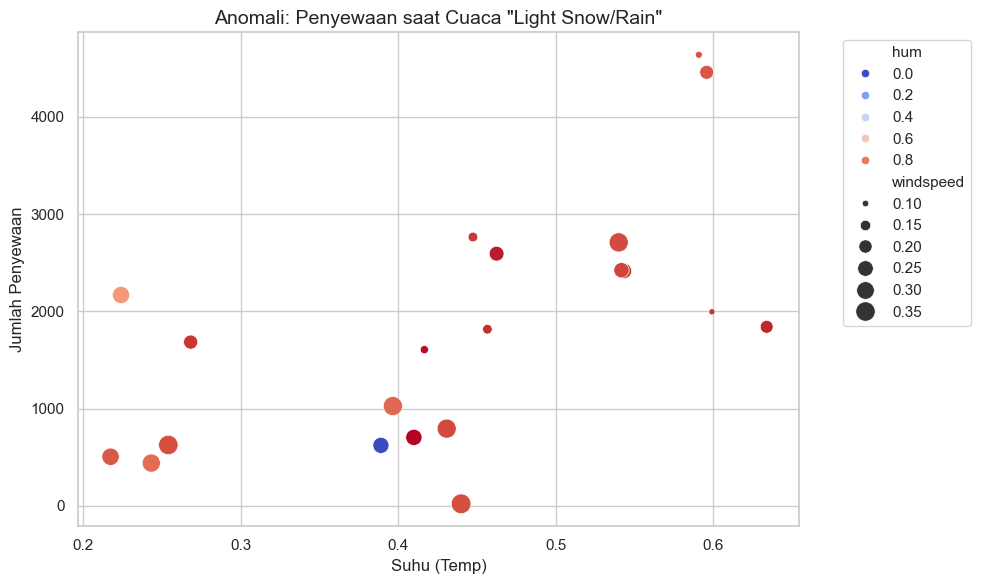

In [7]:
# Scatter plot untuk melihat anomali di Cuaca Buruk
# Filter hanya cuaca Light Snow/Rain
bad_weather_df = day_df[day_df['weathersit'] == 'Light Snow/Rain']

plt.figure(figsize=(10, 6))
sns.scatterplot(data=bad_weather_df, x='temp', y='cnt', hue='hum', size='windspeed', palette='coolwarm', sizes=(20, 200))
plt.title('Anomali: Penyewaan saat Cuaca "Light Snow/Rain"', fontsize=14)
plt.xlabel('Suhu (Temp)')
plt.ylabel('Jumlah Penyewaan')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Pertanyaan 2:

C:\Users\Alya\AppData\Local\Temp\ipykernel_22044\948106770.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=clear_days_grouped, x='weathersit_prev_day', y='cnt', palette='coolwarm')


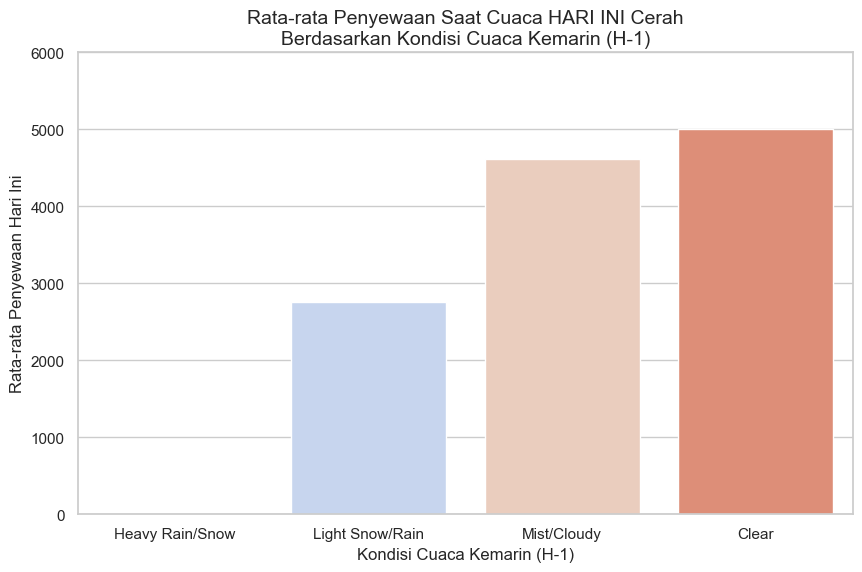

In [10]:
# Efek Psikologis Cuaca Hari Kemarin / Lagging Effec
# Filter data: Hanya ambil hari ini (H) yang cuacanya Clear/Cerah
clear_days = day_df[day_df['weathersit'] == 'Clear']

# Kelompok berdasarkan cuaca kemarin (H-1) (abaikan NaN di baris pertama)
clear_days_grouped = clear_days.dropna(subset=['weathersit_prev_day']).groupby('weathersit_prev_day')['cnt'].mean().reset_index()

# Urutan data agar grafik rapi (dari cuaca terburuk ke terbaik)
weather_order = ['Heavy Rain/Snow', 'Light Snow/Rain', 'Mist/Cloudy', 'Clear']
clear_days_grouped['weathersit_prev_day'] = pd.Categorical(clear_days_grouped['weathersit_prev_day'], categories=weather_order, ordered=True)
clear_days_grouped = clear_days_grouped.sort_values('weathersit_prev_day')

# Visualisasi
plt.figure(figsize=(10, 6))
sns.barplot(data=clear_days_grouped, x='weathersit_prev_day', y='cnt', palette='coolwarm')
plt.title('Rata-rata Penyewaan Saat Cuaca HARI INI Cerah\nBerdasarkan Kondisi Cuaca Kemarin (H-1)', fontsize=14)
plt.xlabel('Kondisi Cuaca Kemarin (H-1)')
plt.ylabel('Rata-rata Penyewaan Hari Ini')
plt.ylim(0, 6000) # Set batas Y agar perbedaan terlihat jelas
plt.show()

**Insight:** (Opsional)
- Titik Terendah: Terjadi saat cuaca Heavy Rain/Snow (titik terendah mencapai 22 penyewaan). Cuaca ini benar-benar mematikan minat bersepeda.
- Anomali: Pada cuaca Light Snow/Rain, terdapat titik di mana penyewaan tetap tinggi (diatas 4000). Jika kita lihat scatter plot, anomali ini terjadi ketika suhu cukup hangat dan kecepatan angin rendah, sehingga hujan ringan tidak terlalu menghalangi pengguna.
- Grafik batang membuktikan adanya efek trauma. Meskipun cuaca hari ini cerah, jika kemarin cuacanya buruk (Heavy Rain/Snow), rata-rata penyewaan hari ini tertinggal jauh lebih rendah dibandingkan jika kemarin cuacanya juga cerah.
- Grafik batang juga menunjukkan pengguna melihat prakiraan cuaca jangka panjang atau sudah merencanakan aktivitas lain saat cuaca buruk kemarin.

## Analisis Lanjutan (Opsional)

In [11]:
# Korelasi Windspeed vs Cnt khusus hari cerah
clear_corr = clear_days['windspeed'].corr(clear_days['cnt'])
print(f"Korelasi Kecepatan Angin vs Penyewaan (saat cuaca cerah): {clear_corr:.2f}")

Korelasi Kecepatan Angin vs Penyewaan (saat cuaca cerah): -0.19


**Insight:** (Opsional)
- Meskipun cuaca cerah, jika kecepatan angin (windspeed) tinggi, korelasi negatif menunjukkan angin kencang tetap menurunkan minat pengguna.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Titik Terendah: Penyewaan mendekati nol (bahkan pernah menyentuh angka 22) saat cuaca Heavy Rain/Snow. Anomali: Penyewaan bisa tetap tinggi di tengah cuaca Light Snow/Rain apabila suhu sedang hangat dan kecepatan angin rendah. Ini menandakan pengguna sepeda tidak terlalu takut dengan hujan ringan asalkan faktor pendukung lain nyaman.
- **Conclusion pertanyaan 2:** Terdapat Efek Trauma Cuaca (Lagging Effect). Cuaca buruk di hari kemarin terbukti secara statistik menekan jumlah penyewaan pada hari ini, meskipun cuaca hari ini sedang cerah. Rata-rata penyewaan hari cerah setelah kemarin hujan deras lebih rendah dibanding hari cerah setelah kemarin cerah.

**Rekomendasi Action Item:**
- Mitigasi Cuaca Ekstrem: Saat cuaca Heavy Rain/Snow diprediksi, perusahaan tidak perlu mengeluarkan biaya operasional besar untuk menambah armada. Sebaliknya, alokasikan armada lebih banyak saat cuaca Light Snow/Rain jika suhu sedang hangat, karena ada peluang pasar yang tidak terduga di sana.
- Kampanye "Pemulihan Pasca Hujan": Karena adanya efek trauma cuaca kemarin, jika hari ini cuaca sangat cerah tetapi kemarin hujan deras, tim marketing bisa meluncurkan promo kilat dadakan (misal: Flash Sale sore hari) atau notifikasi push ("Cuaca hari ini cerah! Yuk bersepeda lagi") untuk "memancing" kembali minat pengguna yang masih ragu untuk keluar rumah.
- Fitur Aplikasi Berbasis Data: Tambahkan fitur peringatan dini di aplikasi jika kecepatan angin (windspeed) tinggi, karena angin kencang terbukti menurunkan minat meskipun cuaca sedang cerah.
